# Notebook 05 — Evaluasi Struktur Klasterisasi (Silhouette Coefficient & Davies-Bouldin Index)

**Judul Penelitian:** Penentuan Lokasi Rumah Pompa Air Pengendali Banjir Menggunakan Klasterisasi DBSCAN dan K-Means (Studi Kasus: Kota Surabaya)

## Tujuan Notebook Ini
1. Memeriksa prasyarat matematis evaluasi ($2 \le K < N$ pada titik Non-Noise, tanpa mengikutsertakan titik Noise) sebelum menghitung metrik pada koordinat proyeksi `easting` & `northing` (`EPSG:32749`).
2. Menghitung **Silhouette Coefficient (SC)** dan **Davies-Bouldin Index (DBI)** untuk **$K$ terpilih** pada masing-masing 7 rayon pematusan.
3. Menganalisis **Silhouette per subcluster** (seluruh 31 subcluster), termasuk menelaah dampak subcluster mikro `RYN-03-C01` (4 titik) di Rayon Wiyung.
4. Melakukan analisis pembanding profil **SC** dan **DBI** di seluruh rentang **$K = 2$ sampai $10$** per rayon terhadap $K$ terpilih dari Elbow Method.
5. Menyimpan seluruh tabel evaluasi ke `outputs/tables/` dan grafik evaluasi ke `outputs/figures/`.

> **Catatan Metodologis Penting:** Silhouette Coefficient dan Davies-Bouldin Index hanya mengevaluasi **kualitas struktur geometris klasterisasi** (kohesi internal & separasi antar-klaster) pada ruang koordinat proyeksi, **bukan** kebutuhan pengendalian banjir, kapasitas hidraulis, atau kelayakan konstruksi rumah pompa.

## 1. Setup Path, Import Modul `src/evaluation.py`, dan Memuat Hasil Tahap 4

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.clustering import DEFAULT_K_RANGE, DEFAULT_KMEANS_N_INIT, DEFAULT_RANDOM_STATE
from src.evaluation import (
    evaluate_selected_kmeans_all_rayons,
    evaluate_k_range_comparison,
    save_evaluation_outputs,
)

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIG_DIR = PROJECT_ROOT / "outputs" / "figures"
TAB_DIR = PROJECT_ROOT / "outputs" / "tables"

pd.set_option("display.max_columns", 25)
pd.set_option("display.width", 180)
plt.rcParams["figure.dpi"] = 120

gdf_kmeans = gpd.read_file(PROCESSED_DIR / "saluran_kmeans_utm49s.gpkg")
gdf_rayon = gpd.read_file(PROCESSED_DIR / "rayon_pematusan_utm49s.gpkg").sort_values("id_rayon").reset_index(drop=True)

print(f"Dataset hasil K-Means : {len(gdf_kmeans):,} titik | CRS: {gdf_kmeans.crs}")
print(f"  - Dievaluasi (Non-Noise) : {int(gdf_kmeans['is_non_noise'].sum()):,} titik")
print(f"  - Dikecualikan (Noise)   : {int((~gdf_kmeans['is_non_noise']).sum()):,} titik")

Dataset hasil K-Means : 21,272 titik | CRS: EPSG:32749
  - Dievaluasi (Non-Noise) : 21,108 titik
  - Dikecualikan (Noise)   : 164 titik


## 2. Evaluasi Silhouette Coefficient (SC) dan Davies-Bouldin Index (DBI) pada K Terpilih
- **Silhouette Coefficient (SC)** bernilai `[-1, +1]`: semakin mendekati `+1` berarti titik jauh lebih dekat ke klasternya sendiri dibanding klaster tetangga terdekat. Kategori acuan Kaufman & Rousseeuw (1990): `> 0.70` Kuat, `0.51–0.70` Wajar/Cukup Baik, `0.26–0.50` Lemah, `<= 0.25` Tidak Substansial.
- **Davies-Bouldin Index (DBI)** bernilai `[0, ∞)`: semakin mendekati `0` berarti rasio sebaran internal terhadap jarak antar-centroid semakin baik (klaster semakin kompak dan terpisah).

In [2]:
df_eval_rayon, df_eval_subcluster, sample_sil_dict = evaluate_selected_kmeans_all_rayons(gdf_kmeans)

print("=== EVALUASI K-MEANS++ PER RAYON (K TERPILIH ELBOW + KNEEDLE) ===")
display(df_eval_rayon)

print("\n=== PROFIL SILHOUETTE PER SUBCLUSTER (31 SUBCLUSTER) ===")
display(df_eval_subcluster)

print("\n--- Sorotan Khusus: Subcluster Mikro RYN-03-C01 (Rayon Wiyung) ---")
display(df_eval_subcluster[df_eval_subcluster["nama_rayon"] == "Rayon Wiyung"])

=== EVALUASI K-MEANS++ PER RAYON (K TERPILIH ELBOW + KNEEDLE) ===


,id_rayon,nama_rayon,k_terpilih,jumlah_non_noise,jumlah_noise_dikecualikan,silhouette_score,kategori_silhouette,davies_bouldin_index,sil_min,sil_median,sil_max,jumlah_sil_negatif,persen_sil_negatif,status_validasi
0,RYN-01,Rayon Benowo,5,1147,28,0.5273,Struktur Wajar (0.51-0.70),0.6217,-0.1856,0.5608,0.8240,20,1.74,Valid
1,RYN-02,Rayon Tandes,4,2615,22,0.4836,Struktur Lemah (0.26-0.50),0.6966,-0.0287,0.5406,0.7328,5,0.19,Valid
2,RYN-03,Rayon Wiyung,5,1107,16,0.4864,Struktur Lemah (0.26-0.50),0.5958,-0.0209,0.5054,0.9896,3,0.27,Valid
3,RYN-04,Rayon Jambangan,5,2544,12,0.4439,Struktur Lemah (0.26-0.50),0.8058,-0.0890,0.4769,0.7473,42,1.65,Valid
4,RYN-05,Rayon Rungkut,4,2107,13,0.5017,Struktur Wajar (0.51-0.70),0.7494,-0.1646,0.5931,0.7472,66,3.13,Valid
5,RYN-06,Rayon Genteng,4,3691,27,0.3987,Struktur Lemah (0.26-0.50),0.8414,-0.0678,0.4314,0.6815,50,1.35,Valid
6,RYN-07,Rayon Gubeng,4,7897,46,0.3974,Struktur Lemah (0.26-0.50),0.8944,-0.0518,0.4443,0.6461,78,0.99,Valid
7,MEAN,Rata-rata 7 Rayon (Unweighted),31,21108,164,0.4627,Struktur Lemah (0.26-0.50),0.7436,-0.1856,0.5075,0.9896,264,1.25,Ringkasan Unweighted
8,W-MEAN,Rata-rata Tertimbang Jumlah Titik,31,21108,164,0.4360,Struktur Lemah (0.26-0.50),0.8050,NaN,NaN,NaN,264,1.25,Ringkasan Weighted



=== PROFIL SILHOUETTE PER SUBCLUSTER (31 SUBCLUSTER) ===


,centroid_id,id_rayon,nama_rayon,kmeans_cluster,jumlah_titik,sil_mean,sil_median,sil_min,sil_max,jumlah_sil_negatif,persen_sil_negatif
0,RYN-01-C01,RYN-01,Rayon Benowo,1,40,0.6921,0.7875,0.0788,0.8240,0,0.00
1,RYN-01-C02,RYN-01,Rayon Benowo,2,359,0.6282,0.6711,0.0735,0.7652,0,0.00
2,RYN-01-C03,RYN-01,Rayon Benowo,3,68,0.6279,0.7059,0.3582,0.7559,0,0.00
3,RYN-01-C04,RYN-01,Rayon Benowo,4,310,0.5776,0.6289,0.1900,0.7147,0,0.00
4,RYN-01-C05,RYN-01,Rayon Benowo,5,370,0.3511,0.3825,-0.1856,0.5311,20,5.41
5,RYN-02-C01,RYN-02,Rayon Tandes,1,1340,0.4727,0.5387,0.0071,0.6478,0,0.00
6,RYN-02-C02,RYN-02,Rayon Tandes,2,782,0.4559,0.4976,-0.0015,0.6531,1,0.13
7,RYN-02-C03,RYN-02,Rayon Tandes,3,173,0.5672,0.6832,0.0596,0.7328,0,0.00
8,RYN-02-C04,RYN-02,Rayon Tandes,4,320,0.5520,0.6558,-0.0287,0.7142,4,1.25
9,RYN-03-C01,RYN-03,Rayon Wiyung,1,4,0.9895,0.9895,0.9894,0.9896,0,0.00



--- Sorotan Khusus: Subcluster Mikro RYN-03-C01 (Rayon Wiyung) ---


,centroid_id,id_rayon,nama_rayon,kmeans_cluster,jumlah_titik,sil_mean,sil_median,sil_min,sil_max,jumlah_sil_negatif,persen_sil_negatif
9,RYN-03-C01,RYN-03,Rayon Wiyung,1,4,0.9895,0.9895,0.9894,0.9896,0,0.00
10,RYN-03-C02,RYN-03,Rayon Wiyung,2,155,0.6008,0.6758,0.0678,0.7466,0,0.00
11,RYN-03-C03,RYN-03,Rayon Wiyung,3,394,0.3545,0.3821,-0.0209,0.5427,3,0.76
12,RYN-03-C04,RYN-03,Rayon Wiyung,4,340,0.4309,0.4840,0.0173,0.6274,0,0.00
13,RYN-03-C05,RYN-03,Rayon Wiyung,5,214,0.7251,0.7413,0.4033,0.8104,0,0.00


## 3. Analisis Komparasi Profil SC & DBI pada Rentang $K = 2 \dots 10$ per Rayon
Sebagai penguatan analisis Bab IV, kita menghitung SC dan DBI untuk setiap $K \in \{2, \dots, 10\}$ menggunakan konfigurasi K-Means++ yang identik (`n_init=20`, `random_state=42`), lalu membandingkan posisi **$K$ terpilih Elbow** terhadap **$K$ puncak SC** dan **$K$ minimum DBI**.

In [3]:
df_comp_all, df_comp_summary = evaluate_k_range_comparison(
    gdf_kmeans=gdf_kmeans,
    k_values=DEFAULT_K_RANGE,
    n_init=DEFAULT_KMEANS_N_INIT,
    random_state=DEFAULT_RANDOM_STATE,
)

print("=== RINGKASAN PERBANDINGAN: K ELBOW vs K TERBAIK SC vs K TERBAIK DBI (K=2..10) ===")
display(df_comp_summary)

print("\n=== TABEL SILHOUETTE COEFFICIENT UNTUK K = 2..10 PER RAYON ===")
piv_sc = df_comp_all.pivot(index="nama_rayon", columns="k", values="silhouette_score").loc[gdf_rayon["nama_rayon"].tolist()]
display(piv_sc)

print("\n=== TABEL DAVIES-BOULDIN INDEX UNTUK K = 2..10 PER RAYON ===")
piv_dbi = df_comp_all.pivot(index="nama_rayon", columns="k", values="davies_bouldin_index").loc[gdf_rayon["nama_rayon"].tolist()]
display(piv_dbi)

=== RINGKASAN PERBANDINGAN: K ELBOW vs K TERBAIK SC vs K TERBAIK DBI (K=2..10) ===


,id_rayon,nama_rayon,k_elbow,sc_pada_k_elbow,dbi_pada_k_elbow,k_terbaik_sc,sc_maks_rentang,selisih_sc_vs_maks,k_terbaik_dbi,dbi_min_rentang,selisih_dbi_vs_min
0,RYN-01,Rayon Benowo,5,0.5273,0.6217,2,0.7048,-0.1775,2,0.4176,0.2041
1,RYN-02,Rayon Tandes,4,0.4836,0.6966,2,0.6267,-0.1431,2,0.5594,0.1372
2,RYN-03,Rayon Wiyung,5,0.4864,0.5958,2,0.6437,-0.1573,2,0.4538,0.1420
3,RYN-04,Rayon Jambangan,5,0.4439,0.8058,2,0.5938,-0.1499,2,0.5988,0.2070
4,RYN-05,Rayon Rungkut,4,0.5017,0.7494,5,0.5226,-0.0209,8,0.7289,0.0205
5,RYN-06,Rayon Genteng,4,0.3987,0.8414,2,0.5331,-0.1344,2,0.6599,0.1815
6,RYN-07,Rayon Gubeng,4,0.3974,0.8944,2,0.4263,-0.0289,10,0.7700,0.1244



=== TABEL SILHOUETTE COEFFICIENT UNTUK K = 2..10 PER RAYON ===


k,2,3,4,5,6,7,8,9,10
nama_rayon,,,,,,,,,
Rayon Benowo,0.7048,0.6590,0.5443,0.5273,0.5452,0.5133,0.5088,0.5131,0.5068
Rayon Tandes,0.6267,0.4884,0.4836,0.3912,0.4271,0.4335,0.4403,0.4285,0.4475
Rayon Wiyung,0.6437,0.5576,0.4816,0.4864,0.5338,0.4791,0.4477,0.4507,0.4566
Rayon Jambangan,0.5938,0.4758,0.4473,0.4439,0.4500,0.4380,0.4292,0.4206,0.4155
Rayon Rungkut,0.4747,0.4755,0.5017,0.5226,0.4916,0.4771,0.4711,0.4352,0.4451
Rayon Genteng,0.5331,0.4453,0.3987,0.3899,0.4142,0.4097,0.4087,0.3952,0.3942
Rayon Gubeng,0.4263,0.3995,0.3974,0.3725,0.3776,0.3962,0.3921,0.3910,0.3950



=== TABEL DAVIES-BOULDIN INDEX UNTUK K = 2..10 PER RAYON ===


k,2,3,4,5,6,7,8,9,10
nama_rayon,,,,,,,,,
Rayon Benowo,0.4176,0.4996,0.6440,0.6217,0.5186,0.5717,0.5856,0.5732,0.5829
Rayon Tandes,0.5594,0.7273,0.6966,0.8705,0.7618,0.7741,0.7318,0.7141,0.6695
Rayon Wiyung,0.4538,0.6215,0.7180,0.5958,0.5112,0.6244,0.6773,0.6952,0.6692
Rayon Jambangan,0.5988,0.7919,0.8059,0.8058,0.7780,0.7994,0.8056,0.8286,0.8082
Rayon Rungkut,0.7889,0.7918,0.7494,0.7411,0.7409,0.7401,0.7289,0.8008,0.7759
Rayon Genteng,0.6599,0.7902,0.8414,0.8864,0.8023,0.8335,0.8033,0.8131,0.8069
Rayon Gubeng,0.9235,0.9678,0.8944,0.8664,0.8274,0.7935,0.7818,0.7733,0.7700


## 4. Visualisasi 1 — Perbandingan Silhouette Coefficient dan Davies-Bouldin Index (K Terpilih)

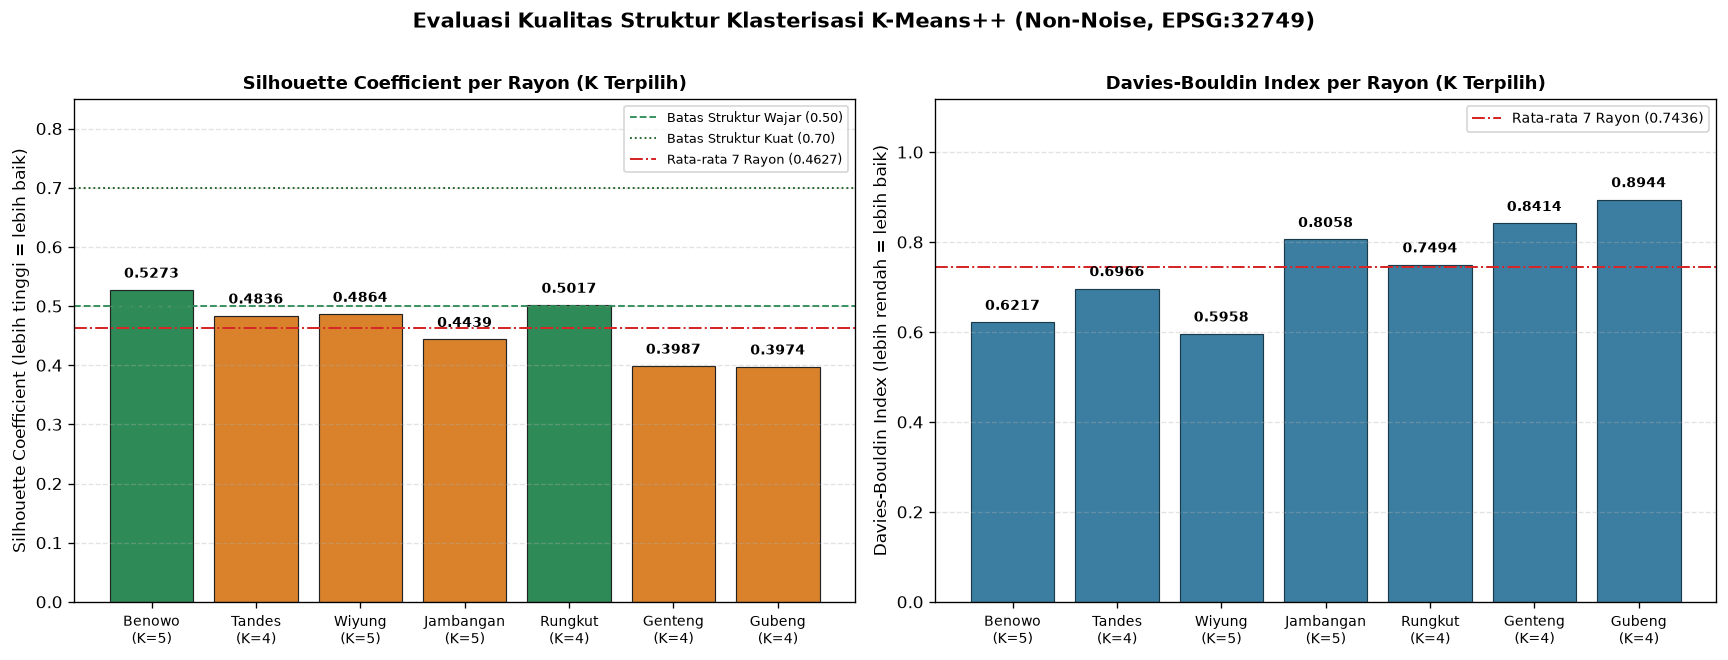

Grafik batang SC & DBI disimpan ke: C:\Skripsi\skripsi-rumah-pompa\outputs\figures\05_evaluasi_sc_dbi_per_rayon.png


In [4]:
df_plot = df_eval_rayon[~df_eval_rayon["id_rayon"].isin(["MEAN", "W-MEAN"])].copy()
short_names = [f"{r['nama_rayon'].replace('Rayon ', '')}\n(K={int(r['k_terpilih'])})" for _, r in df_plot.iterrows()]
x = np.arange(len(short_names))

fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.4))

# Panel Kiri: Silhouette Coefficient
ax = axes[0]
sc_vals = df_plot["silhouette_score"].values
colors_sc = ["#2E8B57" if v > 0.50 else "#D9822B" for v in sc_vals]
bars = ax.bar(x, sc_vals, color=colors_sc, edgecolor="#222222", linewidth=0.7)
ax.axhline(0.50, color="#2E8B57", linestyle="--", linewidth=1.1, label="Batas Struktur Wajar (0.50)")
ax.axhline(0.70, color="#1B5E20", linestyle=":", linewidth=1.1, label="Batas Struktur Kuat (0.70)")
mean_sc = float(df_eval_rayon.loc[df_eval_rayon["id_rayon"] == "MEAN", "silhouette_score"].iloc[0])
ax.axhline(mean_sc, color="#D62728", linestyle="-.", linewidth=1.2, label=f"Rata-rata 7 Rayon ({mean_sc:.4f})")

for b in bars:
    h = b.get_height()
    ax.text(b.get_x() + b.get_width()/2, h + 0.015, f"{h:.4f}", ha="center", va="bottom", fontsize=8.5, fontweight="bold")

ax.set_xticks(x)
ax.set_xticklabels(short_names, fontsize=8.5)
ax.set_ylim(0, max(0.85, sc_vals.max() + 0.12))
ax.set_ylabel("Silhouette Coefficient (lebih tinggi = lebih baik)")
ax.set_title("Silhouette Coefficient per Rayon (K Terpilih)", fontsize=11, fontweight="bold")
ax.legend(loc="upper right", fontsize=8, frameon=True)
ax.grid(axis="y", linestyle="--", alpha=0.35)

# Panel Kanan: Davies-Bouldin Index
ax = axes[1]
dbi_vals = df_plot["davies_bouldin_index"].values
bars2 = ax.bar(x, dbi_vals, color="#3B7EA1", edgecolor="#1B3B4B", linewidth=0.7)
mean_dbi = float(df_eval_rayon.loc[df_eval_rayon["id_rayon"] == "MEAN", "davies_bouldin_index"].iloc[0])
ax.axhline(mean_dbi, color="#D62728", linestyle="-.", linewidth=1.2, label=f"Rata-rata 7 Rayon ({mean_dbi:.4f})")

for b in bars2:
    h = b.get_height()
    ax.text(b.get_x() + b.get_width()/2, h + 0.02, f"{h:.4f}", ha="center", va="bottom", fontsize=8.5, fontweight="bold")

ax.set_xticks(x)
ax.set_xticklabels(short_names, fontsize=8.5)
ax.set_ylim(0, dbi_vals.max() * 1.25)
ax.set_ylabel("Davies-Bouldin Index (lebih rendah = lebih baik)")
ax.set_title("Davies-Bouldin Index per Rayon (K Terpilih)", fontsize=11, fontweight="bold")
ax.legend(loc="upper right", fontsize=8.5, frameon=True)
ax.grid(axis="y", linestyle="--", alpha=0.35)

fig.suptitle("Evaluasi Kualitas Struktur Klasterisasi K-Means++ (Non-Noise, EPSG:32749)", fontsize=12.5, fontweight="bold", y=1.01)
plt.tight_layout()
fig_bar_path = FIG_DIR / "05_evaluasi_sc_dbi_per_rayon.png"
plt.savefig(fig_bar_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Grafik batang SC & DBI disimpan ke: {fig_bar_path}")

## 5. Visualisasi 2 — Silhouette Plot per Subcluster untuk 7 Rayon
Silhouette Plot memperlihatkan distribusi nilai *silhouette* setiap titik anggota pada masing-masing subcluster (`C1..CK`) dibandingkan terhadap rata-rata SC rayon (garis putus-putus merah).

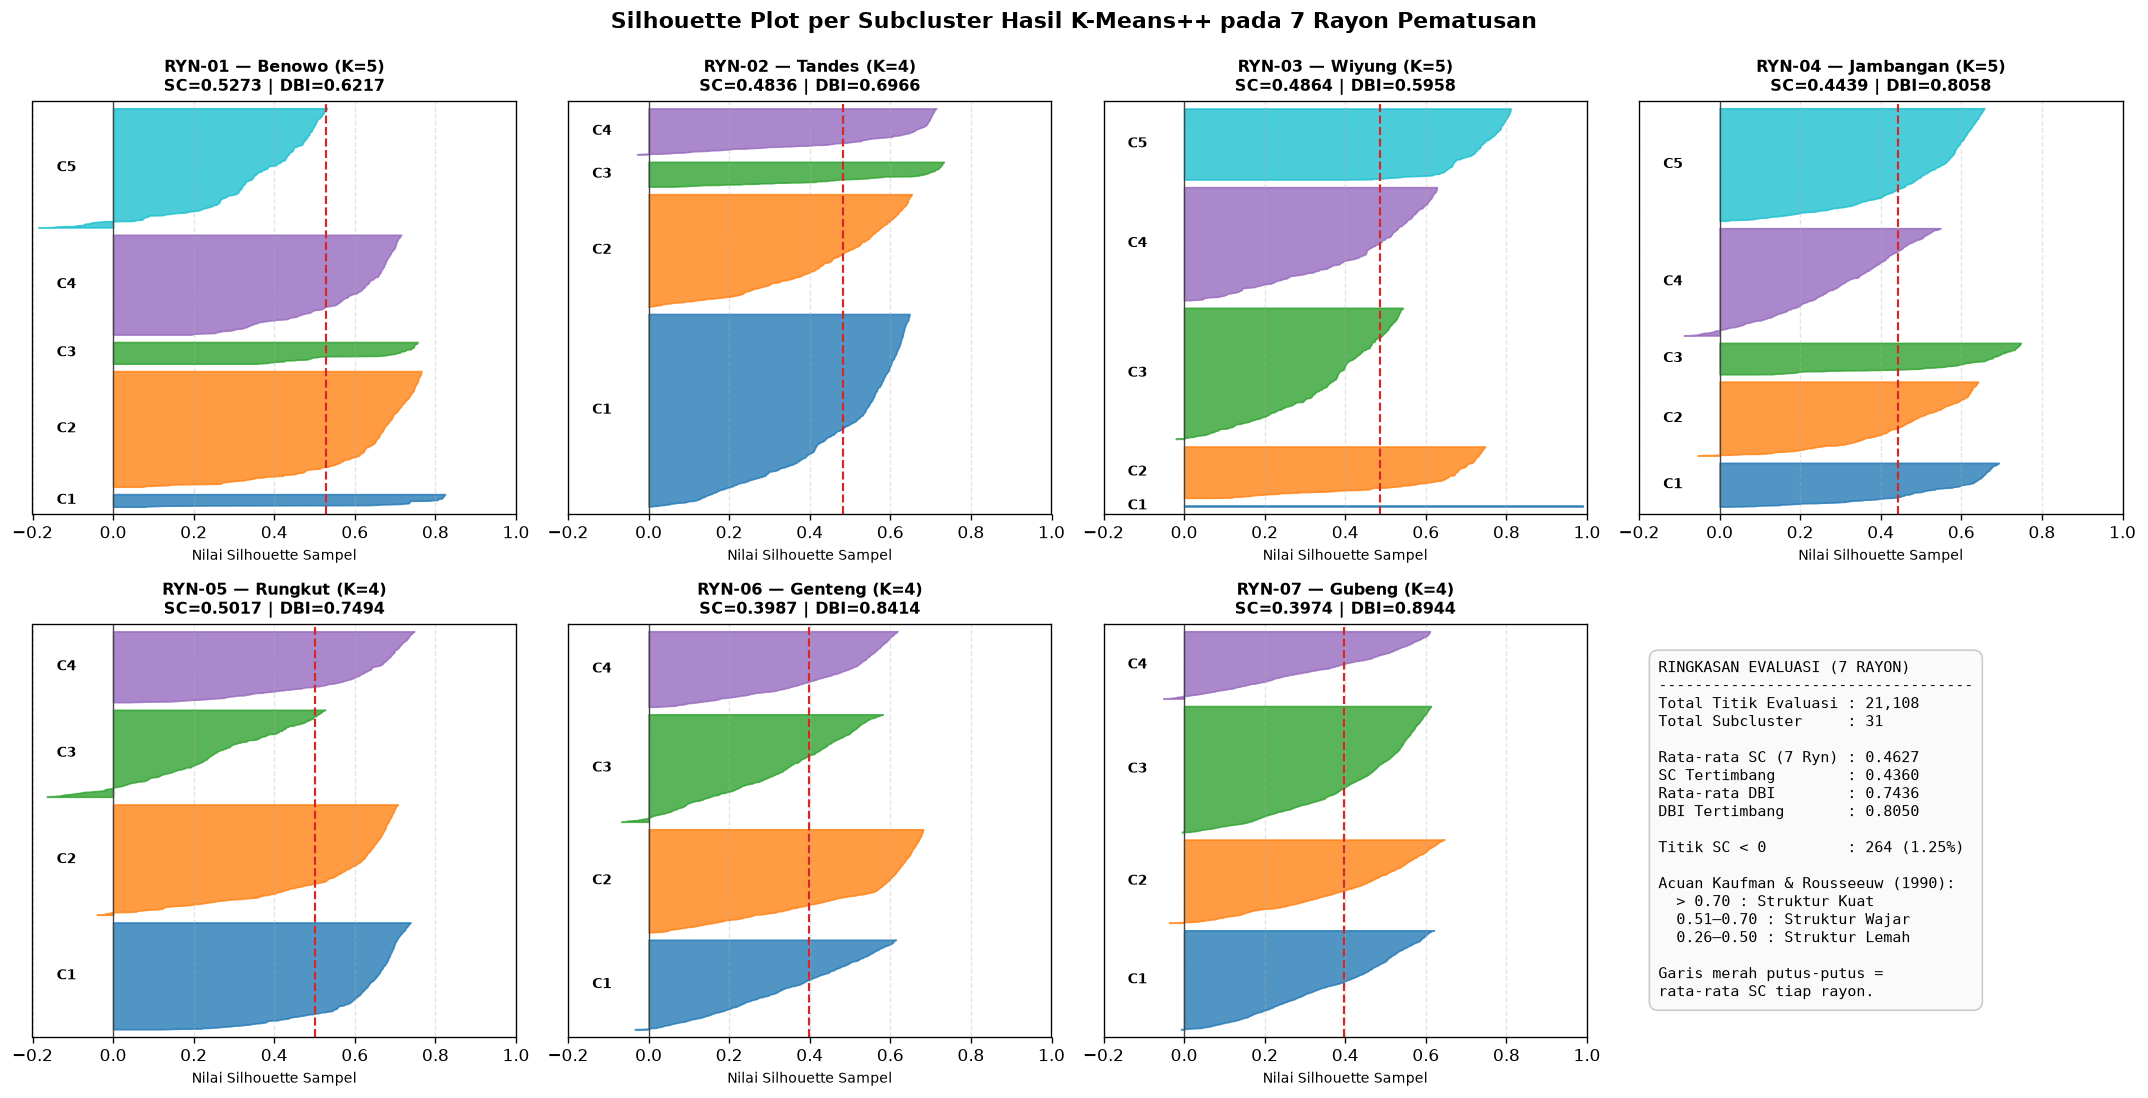

Silhouette Plot disimpan ke: C:\Skripsi\skripsi-rumah-pompa\outputs\figures\05_silhouette_plot_7_rayon.png


In [5]:
PALETTE = [
    "#1F77B4", "#FF7F0E", "#2CA02C", "#9467BD", "#17BECF",
    "#E377C2", "#8C564B", "#BCBD22", "#393B79", "#AD494A"
]

fig, axes = plt.subplots(2, 4, figsize=(18, 9.2))
axes_flat = axes.flatten()

for idx, rname in enumerate(gdf_rayon["nama_rayon"].tolist()):
    ax = axes_flat[idx]
    info = sample_sil_dict[rname]
    labels = info["labels"]
    sil_vals = info["sil_samples"]
    k_sel = info["k_terpilih"]
    sc_mean = info["sc_mean"]
    dbi_val = info["dbi"]

    y_lower = max(10, int(len(sil_vals) * 0.02))
    gap = max(10, int(len(sil_vals) * 0.02))

    for c_idx in range(1, k_sel + 1):
        c_sil = np.sort(sil_vals[labels == c_idx])
        size_c = len(c_sil)
        y_upper = y_lower + size_c
        col = PALETTE[(c_idx - 1) % len(PALETTE)]
        ax.fill_betweenx(np.arange(y_lower, y_upper), 0, c_sil, facecolor=col, edgecolor=col, alpha=0.78)
        ax.text(-0.14, y_lower + 0.5 * size_c, f"C{c_idx}", fontsize=8.2, fontweight="bold", va="center")
        y_lower = y_upper + gap

    ax.axvline(sc_mean, color="#D62728", linestyle="--", linewidth=1.3)
    ax.axvline(0.0, color="#444444", linestyle="-", linewidth=0.8)
    ax.set_xlim(-0.20, 1.0)
    ax.set_ylim(0, y_lower)
    ax.set_yticks([])
    ax.set_xlabel("Nilai Silhouette Sampel", fontsize=8.2)
    ax.set_title(
        f"{info['id_rayon']} — {rname.replace('Rayon ', '')} (K={k_sel})\nSC={sc_mean:.4f} | DBI={dbi_val:.4f}",
        fontsize=9.5,
        fontweight="bold",
    )
    ax.grid(axis="x", linestyle="--", alpha=0.35)

# Panel ke-8: Ringkasan Interpretasi
ax_info = axes_flat[7]
ax_info.axis("off")
row_m = df_eval_rayon[df_eval_rayon["id_rayon"] == "MEAN"].iloc[0]
row_w = df_eval_rayon[df_eval_rayon["id_rayon"] == "W-MEAN"].iloc[0]
txt = (
    "RINGKASAN EVALUASI (7 RAYON)\n"
    "-----------------------------------\n"
    f"Total Titik Evaluasi : {int(row_m['jumlah_non_noise']):,}\n"
    f"Total Subcluster     : {int(row_m['k_terpilih'])}\n\n"
    f"Rata-rata SC (7 Ryn) : {row_m['silhouette_score']:.4f}\n"
    f"SC Tertimbang        : {row_w['silhouette_score']:.4f}\n"
    f"Rata-rata DBI        : {row_m['davies_bouldin_index']:.4f}\n"
    f"DBI Tertimbang       : {row_w['davies_bouldin_index']:.4f}\n\n"
    f"Titik SC < 0         : {int(row_m['jumlah_sil_negatif']):,} ({row_m['persen_sil_negatif']:.2f}%)\n\n"
    "Acuan Kaufman & Rousseeuw (1990):\n"
    "  > 0.70 : Struktur Kuat\n"
    "  0.51–0.70 : Struktur Wajar\n"
    "  0.26–0.50 : Struktur Lemah\n\n"
    "Garis merah putus-putus =\n"
    "rata-rata SC tiap rayon."
)
ax_info.text(0.04, 0.50, txt, va="center", ha="left", fontsize=9.0, family="monospace",
             bbox=dict(boxstyle="round,pad=0.6", fc="#FAFAFA", ec="#CCCCCC"))

fig.suptitle("Silhouette Plot per Subcluster Hasil K-Means++ pada 7 Rayon Pematusan", fontsize=13, fontweight="bold", y=0.99)
plt.tight_layout()
fig_sil_path = FIG_DIR / "05_silhouette_plot_7_rayon.png"
plt.savefig(fig_sil_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Silhouette Plot disimpan ke: {fig_sil_path}")

## 6. Visualisasi 3 — Grafik Komparasi SC & DBI pada Rentang $K = 2 \dots 10$ vs $K$ Terpilih Elbow
Setiap panel menampilkan kurva **Silhouette Coefficient** (biru, sumbu kiri) dan **Davies-Bouldin Index** (oranye, sumbu kanan) untuk $K = 2 \dots 10$, dilengkapi garis vertikal merah penanda **$K$ terpilih dari Elbow Method**.

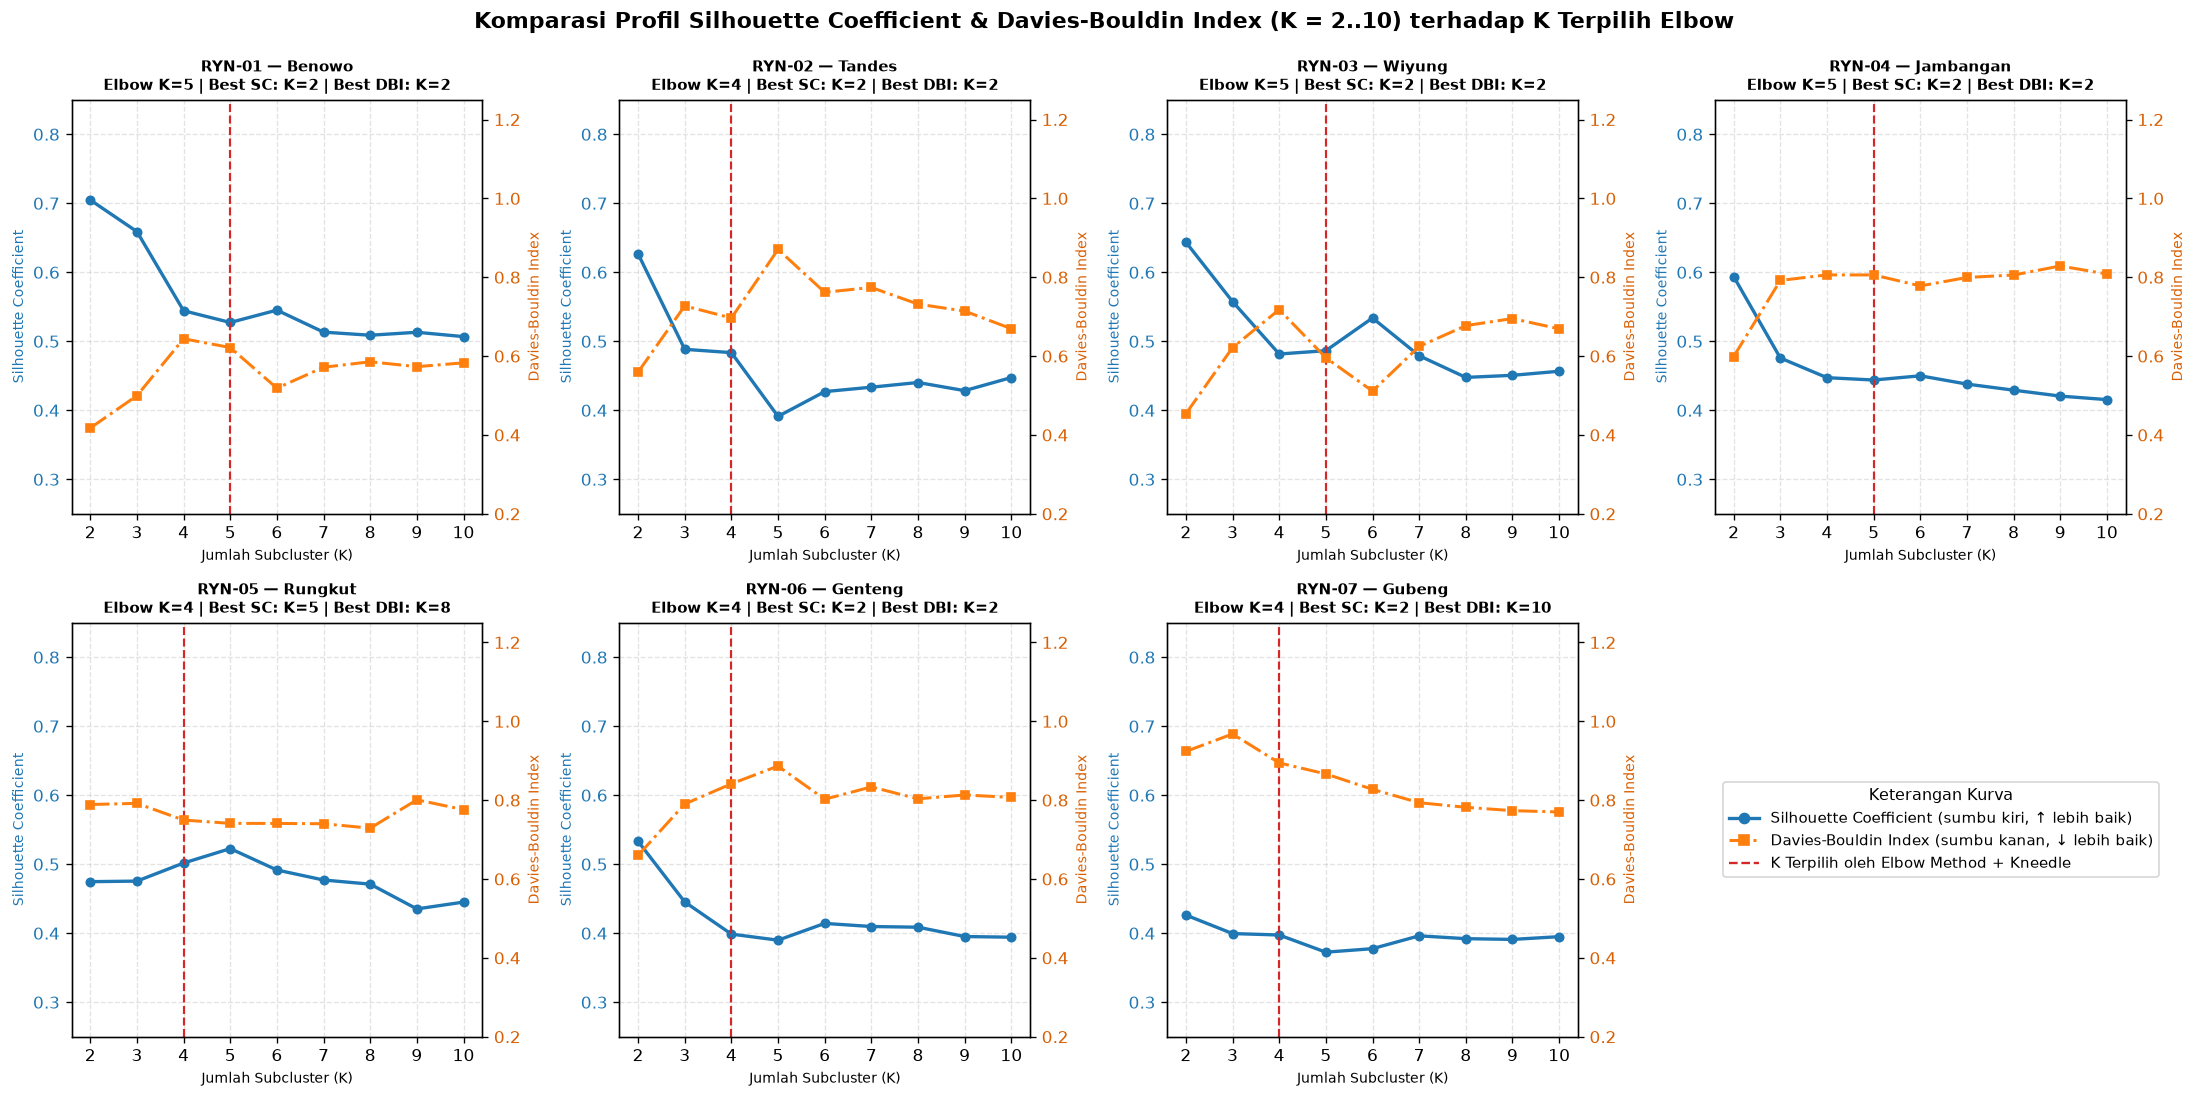

Grafik komparasi K=2..10 disimpan ke: C:\Skripsi\skripsi-rumah-pompa\outputs\figures\05_komparasi_k2_k10_sc_dbi.png


In [6]:
fig, axes = plt.subplots(2, 4, figsize=(18.5, 9.2))
axes_flat = axes.flatten()

for idx, rname in enumerate(gdf_rayon["nama_rayon"].tolist()):
    ax1 = axes_flat[idx]
    sub = df_comp_all[df_comp_all["nama_rayon"] == rname].sort_values("k")
    srow = df_comp_summary[df_comp_summary["nama_rayon"] == rname].iloc[0]
    k_el = int(srow["k_elbow"])

    l1 = ax1.plot(sub["k"], sub["silhouette_score"], marker="o", color="#1F77B4", linewidth=2.0, markersize=5, label="Silhouette (↑ lebih baik)")
    ax1.axvline(k_el, color="#D62728", linestyle="--", linewidth=1.3, label=f"K Elbow = {k_el}")
    ax1.set_xticks(list(DEFAULT_K_RANGE))
    ax1.set_xlabel("Jumlah Subcluster (K)", fontsize=8.2)
    ax1.set_ylabel("Silhouette Coefficient", color="#1F77B4", fontsize=8.2)
    ax1.tick_params(axis="y", labelcolor="#1F77B4")
    ax1.set_ylim(0.25, 0.85)
    ax1.grid(True, linestyle="--", alpha=0.35)

    ax2 = ax1.twinx()
    l2 = ax2.plot(sub["k"], sub["davies_bouldin_index"], marker="s", color="#FF7F0E", linewidth=1.8, linestyle="-.", markersize=4.8, label="DBI (↓ lebih baik)")
    ax2.set_ylabel("Davies-Bouldin Index", color="#D95F02", fontsize=8.2)
    ax2.tick_params(axis="y", labelcolor="#D95F02")
    ax2.set_ylim(0.20, 1.25)

    ax1.set_title(
        f"{srow['id_rayon']} — {rname.replace('Rayon ', '')}\nElbow K={k_el} | Best SC: K={int(srow['k_terbaik_sc'])} | Best DBI: K={int(srow['k_terbaik_dbi'])}",
        fontsize=9.2,
        fontweight="bold",
    )

# Panel ke-8: Legenda Bersama
ax_leg = axes_flat[7]
ax_leg.axis("off")
leg_handles = [
    Line2D([0], [0], color="#1F77B4", marker="o", lw=2, label="Silhouette Coefficient (sumbu kiri, ↑ lebih baik)"),
    Line2D([0], [0], color="#FF7F0E", marker="s", lw=1.8, ls="-.", label="Davies-Bouldin Index (sumbu kanan, ↓ lebih baik)"),
    Line2D([0], [0], color="#D62728", lw=1.4, ls="--", label="K Terpilih oleh Elbow Method + Kneedle"),
]
ax_leg.legend(handles=leg_handles, loc="center left", frameon=True, fontsize=9.0, title="Keterangan Kurva", title_fontsize=9.5)

fig.suptitle("Komparasi Profil Silhouette Coefficient & Davies-Bouldin Index (K = 2..10) terhadap K Terpilih Elbow", fontsize=13, fontweight="bold", y=0.99)
plt.tight_layout()
fig_comp_path = FIG_DIR / "05_komparasi_k2_k10_sc_dbi.png"
plt.savefig(fig_comp_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Grafik komparasi K=2..10 disimpan ke: {fig_comp_path}")

## 7. Validasi Akhir & Penyimpanan Tabel Evaluasi (`outputs/tables/`)

In [7]:
# Validasi otomatis hasil evaluasi
valid_rayons = df_eval_rayon[~df_eval_rayon["id_rayon"].isin(["MEAN", "W-MEAN"])]
assert len(valid_rayons) == 7
assert (valid_rayons["status_validasi"] == "Valid").all()
assert valid_rayons["silhouette_score"].between(-1.0, 1.0).all()
assert (valid_rayons["davies_bouldin_index"] >= 0.0).all()
assert len(df_eval_subcluster) == int(valid_rayons["k_terpilih"].sum())
assert len(df_comp_all) == 7 * len(DEFAULT_K_RANGE)

saved = save_evaluation_outputs(
    tables_dir=TAB_DIR,
    df_eval_rayon=df_eval_rayon,
    df_eval_subcluster=df_eval_subcluster,
    df_comp_all=df_comp_all,
    df_comp_summary=df_comp_summary,
)

print("VALIDASI TAHAP 5 LULUS SEMUA ASSERTION!")
print("Tabel evaluasi berhasil disimpan:")
for k, p in saved.items():
    print(f"  - {k:30s}: {p.relative_to(PROJECT_ROOT)} ({p.stat().st_size:,} bytes)")

VALIDASI TAHAP 5 LULUS SEMUA ASSERTION!
Tabel evaluasi berhasil disimpan:
  - eval_per_rayon_csv            : outputs\tables\05_evaluasi_kmeans_per_rayon.csv (1,239 bytes)
  - eval_per_subcluster_csv       : outputs\tables\05_evaluasi_silhouette_per_subcluster.csv (2,418 bytes)
  - eval_komparasi_k2_k10_csv     : outputs\tables\05_evaluasi_komparasi_k2_k10.csv (3,668 bytes)
  - eval_ringkasan_komparasi_csv  : outputs\tables\05_evaluasi_ringkasan_elbow_vs_sc_dbi.csv (651 bytes)
